# Seleksi Fitur dengan Uji Chi-Square

Dataset: `Dataset_Latihan_Preprocessing.csv`
Target: `churn_3bln` (1 = churn, 0 = tidak churn)

Uji Chi-Square ($\chi^2$) dipakai untuk mengecek apakah sebuah fitur berhubungan dengan churn atau tidak.

- **$H_0$**: fitur tidak berhubungan dengan churn (independen).
- **$H_1$**: fitur berhubungan dengan churn.
- Kalau **p-value < 0,05**, $H_0$ ditolak, artinya fitur dianggap berhubungan dengan churn.

Rumusnya:

$$\chi^2 = \sum_{i=1}^{r} \sum_{j=1}^{c} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$

$O_{ij}$ adalah jumlah data yang benar-benar teramati di sel tabel kontingensi, sedangkan $E_{ij}$ adalah jumlah yang diharapkan kalau fitur dan target tidak berhubungan. Makin jauh $O$ dari $E$, makin besar nilai $\chi^2$.

Langkah-langkah:
1. Load data
2. Cek distribusi target
3. Buat fungsi Chi-Square
4. Contoh tabel kontingensi
5. Hitung Chi-Square semua fitur
6. Visualisasi
7. Pilih fitur dan simpan dataset
8. Kesimpulan

### 1. Load Library dan Dataset

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt

df = pd.read_csv('Dataset_Latihan_Preprocessing.csv')
print(f"Dataset berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom.")
df.head()

Dataset berhasil dimuat: 1000 baris, 22 kolom.


,id_pelanggan,usia_tahun,kota,kanal_akuisisi,tingkat_member,metode_pembayaran,langganan_newsletter,lama_member_bulan,jumlah_transaksi_6bln,rata_nilai_transaksi_rp,...,jumlah_keluhan_6bln,skor_kepuasan,persen_diskon_rata,jumlah_kunjungan_30hari,pengeluaran_bulanan_rp,kode_acak,warna_favorit,negara,kolom_hampir_kosong,churn_3bln
0,PLG0001,34.0,Jakarta,Iklan,Silver,Transfer Bank,Ya,33.0,7.0,280000.0,...,0.0,8.6,29.1,5.0,3380000.0,4262,Biru,Indonesia,NaN,0
1,PLG0002,43.0,Yogyakarta,Marketplace,Gold,E-Wallet,Tidak,15.0,11.0,226000.0,...,NaN,7.6,20.5,14.0,3260000.0,8377,Kuning,Indonesia,NaN,0
2,PLG0003,27.0,Jakarta,Iklan,Bronze,Kartu Kredit,Ya,13.0,9.0,431000.0,...,0.0,10.0,2.1,11.0,5070000.0,7000,Kuning,Indonesia,A,0
3,PLG0004,57.0,Jakarta,Referral,Platinum,COD,Ya,6.0,11.0,324000.0,...,0.0,NaN,29.8,NaN,2740000.0,7210,Kuning,Indonesia,NaN,0
4,PLG0005,27.0,Surabaya,Organik,Silver,Transfer Bank,Tidak,28.0,6.0,NaN,...,0.0,NaN,13.9,5.0,2150000.0,3037,Hijau,Indonesia,NaN,0


**Penjelasan:**

Dataset punya 1000 baris dan 22 kolom (21 fitur + 1 target). Ada fitur kategorikal (misalnya `kota`, `tingkat_member`) dan fitur numerik (misalnya `total_belanja_6bln_rp`). Chi-Square hanya bisa dipakai untuk data kategori, jadi fitur numerik nanti harus diubah dulu menjadi kelompok. Terlihat juga ada nilai kosong (`NaN`) yang perlu ditangani.

### 2. Cek Distribusi Target

In [2]:
target = df['churn_3bln']
print("Jumlah per kelas:")
print(target.value_counts())
print("\nPersentase:")
print((target.value_counts(normalize=True) * 100).round(2))

Jumlah per kelas:
churn_3bln
0    758
1    242
Name: count, dtype: int64

Persentase:
churn_3bln
0    75.8
1    24.2
Name: proportion, dtype: float64


**Penjelasan:**

Ada 758 pelanggan tidak churn (75,8%) dan 242 pelanggan churn (24,2%). Kelas churn lebih sedikit, dan ini berpengaruh ke syarat uji Chi-Square, yaitu nilai harapan $E$ di setiap sel minimal 5.

Untuk kolom churn, $E = \text{jumlah data di kategori} \times 0{,}242$. Supaya $E \ge 5$, setiap kategori minimal harus berisi sekitar $5 / 0{,}242 \approx 21$ baris. Kategori yang isinya terlalu sedikit membuat hasil uji kurang bisa dipercaya.

### 3. Fungsi Chi-Square

Cara menyiapkan data sebelum diuji:
- **Fitur numerik** dibagi menjadi 4 kelompok kuantil dengan `pd.qcut(q=4)`, jadi tiap kelompok isinya sekitar 25% data. `pd.cut` (lebar interval sama) tidak dipakai karena data banyak outlier, sehingga hampir semua data akan masuk ke satu kelompok dan kelompok lain isinya sangat sedikit ($E < 5$).
- **Nilai kosong** dijadikan kategori sendiri, yaitu `'(Missing)'`, supaya tidak ada baris yang dibuang.
- **Tidak perlu scaling**, karena Chi-Square menghitung frekuensi, bukan jarak antar nilai.
- **Tidak pakai One-Hot Encoding**, karena yang mau dinilai adalah kolom aslinya secara utuh (misalnya `kota`), bukan per nilai (`kota_Jakarta`, `kota_Bandung`, dst).
- **`id_pelanggan` tidak dipakai**, karena setiap baris punya ID berbeda.

Fungsi `uji_chi_square()` juga mengembalikan **E min**, yaitu nilai harapan terkecil di tabel, untuk mengecek syarat $E \ge 5$.

In [3]:
def buat_kategori(series_fitur, is_numeric):
    # Numerik -> 4 kelompok kuantil, nilai kosong -> '(Missing)'
    if is_numeric:
        kategori = pd.qcut(series_fitur, q=4, duplicates='drop').astype(str)
        return kategori.where(series_fitur.notna(), '(Missing)')
    return series_fitur.astype(object).fillna('(Missing)').astype(str)


def uji_chi_square(series_fitur, series_target, is_numeric=False):
    kategori = buat_kategori(series_fitur, is_numeric)
    tabel = pd.crosstab(kategori, series_target)       # tabel kontingensi (O)

    if tabel.shape[0] < 2:                              # hanya 1 kategori, tidak bisa diuji
        return 0.0, 1.0, 0, np.nan

    chi2, p_val, dof, expected = chi2_contingency(tabel)
    return chi2, p_val, dof, expected.min()

print("Fungsi buat_kategori() dan uji_chi_square() siap digunakan.")

Fungsi buat_kategori() dan uji_chi_square() siap digunakan.


**Penjelasan:**

Sel ini hanya mendefinisikan fungsi:
- `buat_kategori()` mengubah fitur menjadi kategori.
- `uji_chi_square()` membuat tabel kontingensi, lalu mengembalikan nilai $\chi^2$, p-value, derajat bebas (df), dan E min.

Derajat bebas dihitung dengan $df = (\text{jumlah kategori} - 1) \times (\text{jumlah kelas target} - 1)$. Karena targetnya 2 kelas, $df = \text{jumlah kategori} - 1$.

### 4. Contoh Tabel Kontingensi: `jumlah_keluhan_6bln`

Supaya cara kerja Chi-Square lebih jelas, berikut nilai $O$, $E$, dan kontribusi $\chi^2$ untuk setiap kategori jumlah keluhan.

In [4]:
kategori = buat_kategori(df['jumlah_keluhan_6bln'], is_numeric=False)
observed = pd.crosstab(kategori, target)
chi2, p_val, dof, expected = chi2_contingency(observed)
expected = pd.DataFrame(expected, index=observed.index, columns=observed.columns)

contoh = pd.DataFrame({
    'O tidak churn': observed[0],
    'O churn': observed[1],
    'E tidak churn': expected[0].round(1),
    'E churn': expected[1].round(1),
    'Kontribusi chi2': ((observed - expected) ** 2 / expected).sum(axis=1).round(2),
})
display(contoh)
print(f"Chi-Square = {chi2:.2f}, df = {dof}, p-value = {p_val:.2e}")

,O tidak churn,O churn,E tidak churn,E churn,Kontribusi chi2
jumlah_keluhan_6bln,,,,,
(Missing),34,7,31.1,9.9,1.14
0.0,535,94,476.8,152.2,29.38
1.0,53,28,61.4,19.6,4.75
2.0,58,26,63.7,20.3,2.09
3.0,46,32,59.1,18.9,12.04
4.0,32,55,65.9,21.1,72.21


Chi-Square = 121.59, df = 5, p-value = 1.45e-24


**Penjelasan:**

- Kalau keluhan tidak berhubungan dengan churn, pelanggan dengan 0 keluhan seharusnya ada sekitar 152 yang churn (E). Kenyataannya hanya 94 (O), jauh lebih sedikit.
- Sebaliknya, pada pelanggan dengan 4 keluhan, harapannya hanya sekitar 21 yang churn, tapi kenyataannya ada 55.
- Kontribusi terbesar ada di kategori **4.0** (72,21) dan **0.0** (29,38), karena di dua kelompok ini selisih $O$ dan $E$ paling besar.
- Totalnya $\chi^2 = 121{,}59$ dengan df = 5 (6 kategori - 1) dan p-value sangat kecil (≈ $10^{-24}$), jadi $H_0$ ditolak: jumlah keluhan berhubungan dengan churn.
- Nilai E paling kecil adalah 9,9 (kategori `(Missing)` untuk churn), masih di atas 5, jadi syarat uji terpenuhi.

### 5. Hitung Chi-Square Semua Fitur

Aturan yang dipakai:
- Kolom angka dengan lebih dari 10 nilai unik dianggap numerik dan dibagi 4 kuantil. Sisanya dianggap kategorikal.
- p-value < 0,05: signifikan (tolak $H_0$).
- `id_pelanggan` tetap dihitung supaya terlihat masalahnya, tapi langsung dieliminasi.

In [5]:
def is_numerik_kontinu(series, batas_unik=10):
    try:
        nilai = series.dropna().astype(float)
    except (ValueError, TypeError):
        return False
    return nilai.nunique() > batas_unik

daftar_fitur = [c for c in df.columns if c != 'churn_3bln']
hasil_uji = []

for col in daftar_fitur:
    if col == 'id_pelanggan':
        chi2, p_val, dof, e_min = uji_chi_square(df[col], target)
        tipe, status = 'Identifier', 'Dieliminasi (ID unik)'
    else:
        is_num = is_numerik_kontinu(df[col])
        chi2, p_val, dof, e_min = uji_chi_square(df[col], target, is_numeric=is_num)
        tipe = 'Numerik (4 Kuantil)' if is_num else 'Kategorikal'
        status = 'Signifikan (Tolak H0)' if p_val < 0.05 else 'Tidak Signifikan'

    hasil_uji.append({'Fitur': col, 'Tipe': tipe, 'Chi2': chi2, 'df': dof,
                      'p-value': p_val, 'E min': e_min, 'Status': status})

df_chi2 = pd.DataFrame(hasil_uji).sort_values(by='Chi2', ascending=False).reset_index(drop=True)
df_chi2.round({'Chi2': 2, 'E min': 1})

,Fitur,Tipe,Chi2,df,p-value,E min,Status
0,id_pelanggan,Identifier,1000.00,999,4.851315e-01,0.2,Dieliminasi (ID unik)
1,hari_sejak_transaksi_terakhir,Numerik (4 Kuantil),123.54,4,9.347539e-26,9.4,Signifikan (Tolak H0)
2,jumlah_keluhan_6bln,Kategorikal,121.59,5,1.445944e-24,9.9,Signifikan (Tolak H0)
3,skor_kepuasan,Numerik (4 Kuantil),90.75,4,9.105464e-19,25.4,Signifikan (Tolak H0)
4,jumlah_transaksi_6bln,Numerik (4 Kuantil),24.42,4,6.572858e-05,8.7,Signifikan (Tolak H0)
5,jumlah_kunjungan_30hari,Numerik (4 Kuantil),21.36,4,2.686014e-04,6.8,Signifikan (Tolak H0)
6,total_belanja_6bln_rp,Numerik (4 Kuantil),16.58,4,2.328594e-03,15.0,Signifikan (Tolak H0)
7,kode_acak,Numerik (4 Kuantil),6.65,3,8.390054e-02,60.5,Tidak Signifikan
8,persen_diskon_rata,Numerik (4 Kuantil),6.17,4,1.870298e-01,13.8,Tidak Signifikan
9,lama_member_bulan,Numerik (4 Kuantil),5.14,4,2.736886e-01,10.2,Tidak Signifikan


**Penjelasan:**

- **`id_pelanggan`** punya $\chi^2 = 1000$ (paling besar), tapi p-value-nya 0,485 (tidak signifikan) karena df-nya 999. Nilai E min-nya juga hanya 0,2, jadi syarat $E \ge 5$ sama sekali tidak terpenuhi. Kolom ini dieliminasi.
- **6 fitur signifikan** (p < 0,05): `hari_sejak_transaksi_terakhir`, `jumlah_keluhan_6bln`, `skor_kepuasan`, `jumlah_transaksi_6bln`, `jumlah_kunjungan_30hari`, dan `total_belanja_6bln_rp`. Tiga fitur teratas p-value-nya sangat kecil ($10^{-18}$ sampai $10^{-26}$), jadi hubungannya dengan churn sangat kuat.
- **Fitur lainnya tidak signifikan** (p > 0,05). `kode_acak` p-value-nya 0,084, paling dekat ke 0,05, tapi tetap tidak signifikan. `negara` nilainya 0 karena isinya hanya satu kategori.
- **Syarat E ≥ 5**: semua fitur selain `id_pelanggan` punya E min ≥ 5 (paling kecil 5,1 di `langganan_newsletter`), jadi hasil ujinya bisa dipakai.
- Nilai $\chi^2$ tidak bisa langsung dibandingkan kalau df-nya berbeda. Contohnya, `kode_acak` (df = 3) dan `persen_diskon_rata` (df = 4) nilai $\chi^2$-nya mirip, tapi p-value-nya berbeda. Karena itu keputusan akhir tetap pakai p-value.

### 6. Visualisasi

Grafik nilai $\chi^2$ tiap fitur (`id_pelanggan` tidak ditampilkan). Hijau = signifikan (p < 0,05), abu-abu = tidak signifikan. Garis merah adalah nilai kritis $\chi^2$ untuk df = 4 dan $\alpha$ = 0,05 (9,488), yang berlaku untuk fitur numerik dengan 5 kategori (4 kuantil + Missing).

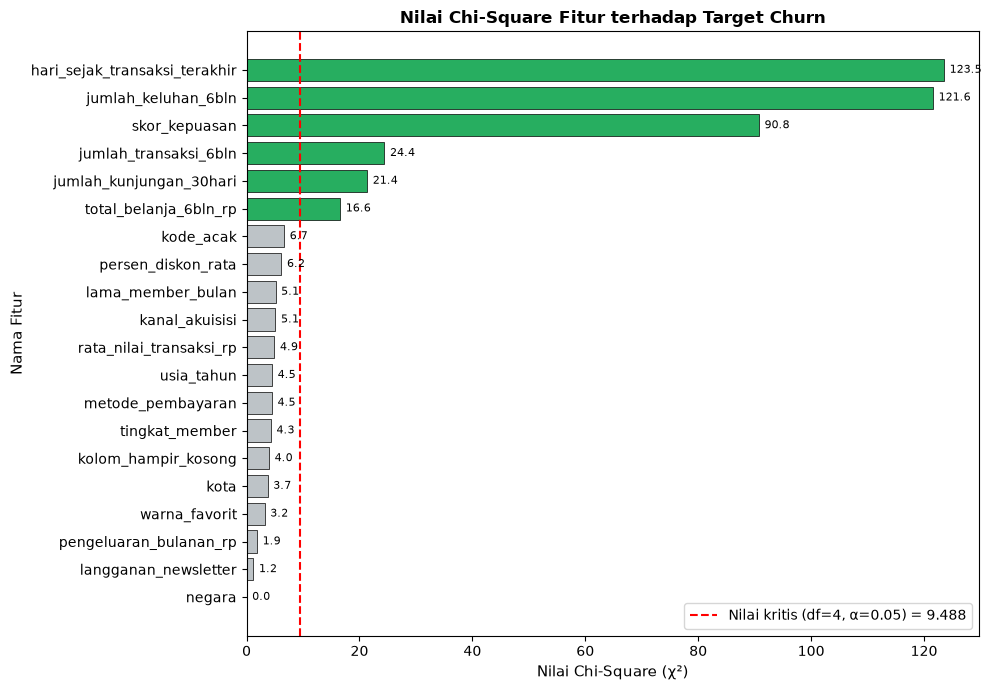

In [6]:
df_plot = df_chi2[df_chi2['Fitur'] != 'id_pelanggan'].sort_values(by='Chi2', ascending=True)
warna = ['#27ae60' if p < 0.05 else '#bdc3c7' for p in df_plot['p-value']]

plt.figure(figsize=(10, 7))
plt.barh(df_plot['Fitur'], df_plot['Chi2'], color=warna, edgecolor='black', linewidth=0.5)
plt.axvline(x=9.488, color='red', linestyle='--', label='Nilai kritis (df=4, α=0.05) = 9.488')

for nama, nilai in zip(df_plot['Fitur'], df_plot['Chi2']):
    plt.text(nilai + 1, nama, f'{nilai:.1f}', va='center', fontsize=8)

plt.title('Nilai Chi-Square Fitur terhadap Target Churn', fontsize=12, fontweight='bold')
plt.xlabel('Nilai Chi-Square (χ²)', fontsize=11)
plt.ylabel('Nama Fitur', fontsize=11)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Penjelasan:**

Tiga fitur teratas nilainya jauh di atas fitur lain (90-124), sedangkan tiga fitur hijau berikutnya ada di kisaran 16-25. Semua fitur hijau berada di kanan garis merah. Fitur abu-abu semuanya di kiri garis (nilainya di bawah 7), jadi tidak cukup kuat untuk menolak $H_0$.

### 7. Pilih Fitur dan Simpan Dataset

Fitur yang dipakai adalah fitur dengan p-value < 0,05, kecuali `id_pelanggan`. Hasilnya disimpan ke `Dataset_Hasil_Seleksi_Chi_Square.csv`.

In [7]:
fitur_terpilih = df_chi2[
    (df_chi2['p-value'] < 0.05) & (df_chi2['Fitur'] != 'id_pelanggan')
]['Fitur'].tolist()
fitur_dibuang = [f for f in daftar_fitur if f not in fitur_terpilih]

print(f"Fitur TERPILIH ({len(fitur_terpilih)} fitur, p-value < 0.05):")
for i, f in enumerate(fitur_terpilih, 1):
    baris = df_chi2.loc[df_chi2['Fitur'] == f].iloc[0]
    print(f"  {i}. {f:30} -> Chi2 = {baris['Chi2']:6.2f}, p-value = {baris['p-value']:.2e}")

print(f"\nFitur DIBUANG ({len(fitur_dibuang)} fitur):")
print("  " + ", ".join(fitur_dibuang))

df_final = df[fitur_terpilih + ['churn_3bln']].copy()
df_final.to_csv('Dataset_Hasil_Seleksi_Chi_Square.csv', index=False)
print(f"\nDataset disimpan ke 'Dataset_Hasil_Seleksi_Chi_Square.csv' dengan dimensi {df_final.shape}.")

Fitur TERPILIH (6 fitur, p-value < 0.05):
  1. hari_sejak_transaksi_terakhir  -> Chi2 = 123.54, p-value = 9.35e-26
  2. jumlah_keluhan_6bln            -> Chi2 = 121.59, p-value = 1.45e-24
  3. skor_kepuasan                  -> Chi2 =  90.75, p-value = 9.11e-19
  4. jumlah_transaksi_6bln          -> Chi2 =  24.42, p-value = 6.57e-05
  5. jumlah_kunjungan_30hari        -> Chi2 =  21.36, p-value = 2.69e-04
  6. total_belanja_6bln_rp          -> Chi2 =  16.58, p-value = 2.33e-03

Fitur DIBUANG (15 fitur):
  id_pelanggan, usia_tahun, kota, kanal_akuisisi, tingkat_member, metode_pembayaran, langganan_newsletter, lama_member_bulan, rata_nilai_transaksi_rp, persen_diskon_rata, pengeluaran_bulanan_rp, kode_acak, warna_favorit, negara, kolom_hampir_kosong

Dataset disimpan ke 'Dataset_Hasil_Seleksi_Chi_Square.csv' dengan dimensi (1000, 7).


**Penjelasan:**

- Dari 21 kolom, ada 6 fitur yang dipakai dan 15 kolom yang dibuang (`id_pelanggan` + 14 fitur yang tidak signifikan).
- Dataset baru berukuran (1000, 7): 6 fitur + target, jumlah baris tetap 1000.
- Fitur yang terpilih sama persis dengan hasil Information Gain, hanya urutan ke-4 sampai ke-6 yang berbeda.
- Dataset ini masih berisi nilai kosong dan outlier dari data asli, jadi tetap perlu dibersihkan sebelum dipakai untuk training model.

### 8. Kesimpulan

- Ada 6 fitur yang berhubungan signifikan dengan churn: `hari_sejak_transaksi_terakhir`, `jumlah_keluhan_6bln`, `skor_kepuasan`, `jumlah_transaksi_6bln`, `jumlah_kunjungan_30hari`, dan `total_belanja_6bln_rp`.
- Fitur demografis dan atribut lain (usia, kota, metode pembayaran, warna favorit, negara, dll) tidak berhubungan signifikan dengan churn.

Kekurangan Chi-Square:
1. Fitur numerik harus dikelompokkan dulu, dan hasilnya bisa berubah tergantung jumlah kelompok (di sini 4 kuantil).
2. Hanya menunjukkan **ada atau tidaknya** hubungan, bukan seberapa kuat atau ke arah mana hubungannya.
3. Menilai fitur satu per satu, jadi tidak bisa mendeteksi fitur yang saling mirip (redundan).
4. Dengan data yang banyak, hubungan yang sangat lemah pun bisa jadi signifikan.